# Feature Engineering



## Predictive Modeling and Risk Scoring for Bank Customer Churn



### Objective

Create meaningful customer features using the findings from exploratory data analysis. The transformations are implemented in the reusable Python module `src/feature_engineering.py`.



### Selected engineered features

- **HasBalance:** 1 when customer balance is greater than zero; otherwise 0.

- **AgeGroup:** Ordered customer age segments: `<30`, `30-39`, `40-49`, `50-59`, `60+`.



Original `Age` and `Balance` columns are retained.

## 1. Feature Selection Rationale



The EDA identified differences in churn behavior across balance status and age groups.



| Feature | Decision | Reason |

|---|---|---|

| HasBalance | Selected | Customers with a positive balance showed a different churn rate from zero-balance customers. |

| AgeGroup | Selected | Churn behavior varied substantially across age ranges. |

| BalanceSalaryRatio | Deferred | Extreme skew and unusually large ratios require further investigation. |

| ProductActivity | Deferred | Some combinations have very small sample sizes. |

| TenureGroup | Deferred | Churn differences across tenure groups were weak. |



These are exploratory associations, not evidence of causation. The usefulness of the selected features must ultimately be evaluated through model validation.

## 2. Imports and Configuration

In [1]:
from pathlib import Path

import sys



import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns



PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data/raw/european-bank.csv").exists():

    PROJECT_ROOT = PROJECT_ROOT.parent



if not (PROJECT_ROOT / "data/raw/european-bank.csv").exists():

    raise FileNotFoundError("Could not locate data/raw/european-bank.csv")



if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(0, str(PROJECT_ROOT))



from src.data_quality import validate_dataset

from src.feature_engineering import engineer_features



pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")



print(f"Project root: {PROJECT_ROOT}")

Project root: /home/dell/unified-mentor/ml-internship/projects/eurobank-customer-churn-prediction


## 3. Load the Original Dataset

In [2]:
raw_data_path = PROJECT_ROOT / "data/raw/european-bank.csv"

df = pd.read_csv(raw_data_path)



print(f"Dataset shape: {df.shape}")

display(df.head())

Dataset shape: (10000, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 4. Validate the Original Dataset



Feature engineering should only proceed after the input dataset passes the project's data-quality checks.

In [3]:
validation_results = validate_dataset(df)

validation_df = pd.DataFrame(validation_results)



display(validation_df)



failed_checks = validation_df[validation_df["status"] != "PASS"]



if not failed_checks.empty:

    raise ValueError("Dataset validation failed. Resolve the issues before feature engineering.")



print(f"All {len(validation_df)} data-quality checks passed.")

,check,status,details
0,Required columns,PASS,Missing: []; Unexpected: []
1,Missing values,PASS,Total missing values: 0
2,Duplicate rows,PASS,Duplicate rows: 0
3,Customer ID uniqueness,PASS,Duplicate customer IDs: 0
4,Target values,PASS,"Observed values: [np.int64(0), np.int64(1)]"
5,HasCrCard binary validation,PASS,"Observed values: [np.int64(0), np.int64(1)]"
6,IsActiveMember binary validation,PASS,"Observed values: [np.int64(0), np.int64(1)]"
7,Exited binary validation,PASS,"Observed values: [np.int64(0), np.int64(1)]"
8,Geography categorical validation,PASS,Invalid values: []
9,Gender categorical validation,PASS,Invalid values: []


All 26 data-quality checks passed.


## 5. Apply Feature Engineering



The notebook calls the reusable transformation function rather than duplicating its logic. The original DataFrame remains unchanged.

In [4]:
original_columns = df.columns.tolist()

engineered_df = engineer_features(df)



print(f"Original shape:   {df.shape}")

print(f"Engineered shape: {engineered_df.shape}")

print(f"New columns: {sorted(set(engineered_df.columns) - set(original_columns))}")



assert df.columns.tolist() == original_columns

assert engineered_df.shape[0] == df.shape[0]

assert {"HasBalance", "AgeGroup"}.issubset(engineered_df.columns)



display(engineered_df.head())

Original shape:   (10000, 14)
Engineered shape: (10000, 16)
New columns: ['AgeGroup', 'HasBalance']


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasBalance,AgeGroup
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0,40-49
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,40-49
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,40-49
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,30-39
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1,40-49


## 6. Inspect the Engineered Features

In [5]:
print("HasBalance distribution")

display(engineered_df["HasBalance"].value_counts().sort_index().rename_axis("HasBalance").to_frame("Customer Count"))



print("AgeGroup distribution")

display(engineered_df["AgeGroup"].value_counts(sort=False).rename_axis("AgeGroup").to_frame("Customer Count"))



print("Missing values in engineered features")

display(engineered_df[["HasBalance", "AgeGroup"]].isna().sum().to_frame("Missing Values"))

HasBalance distribution


,Customer Count
HasBalance,
0,3617
1,6383


AgeGroup distribution


,Customer Count
AgeGroup,
<30,1641
30-39,4346
40-49,2618
50-59,869
60+,526


Missing values in engineered features


,Missing Values
HasBalance,0
AgeGroup,0


## 7. Engineered Features vs. Customer Churn



Compare customer counts and churn rates across the new feature categories. Churn rate is the mean of the binary `Exited` target.

In [6]:
def churn_summary(data, feature):

    summary = (

        data.groupby(feature, observed=False)["Exited"]

        .agg(Customer_Count="count", Churn_Rate="mean")

    )

    summary["Churn_Rate"] *= 100

    return summary



balance_churn = churn_summary(engineered_df, "HasBalance")

age_churn = churn_summary(engineered_df, "AgeGroup")



print("Churn by balance status")

display(balance_churn.round(2))



print("Churn by age group")

display(age_churn.round(2))

Churn by balance status


,Customer_Count,Churn_Rate
HasBalance,,
0,3617,13.82
1,6383,24.08


Churn by age group


,Customer_Count,Churn_Rate
AgeGroup,,
<30,1641,7.56
30-39,4346,10.88
40-49,2618,30.79
50-59,869,56.04
60+,526,27.95


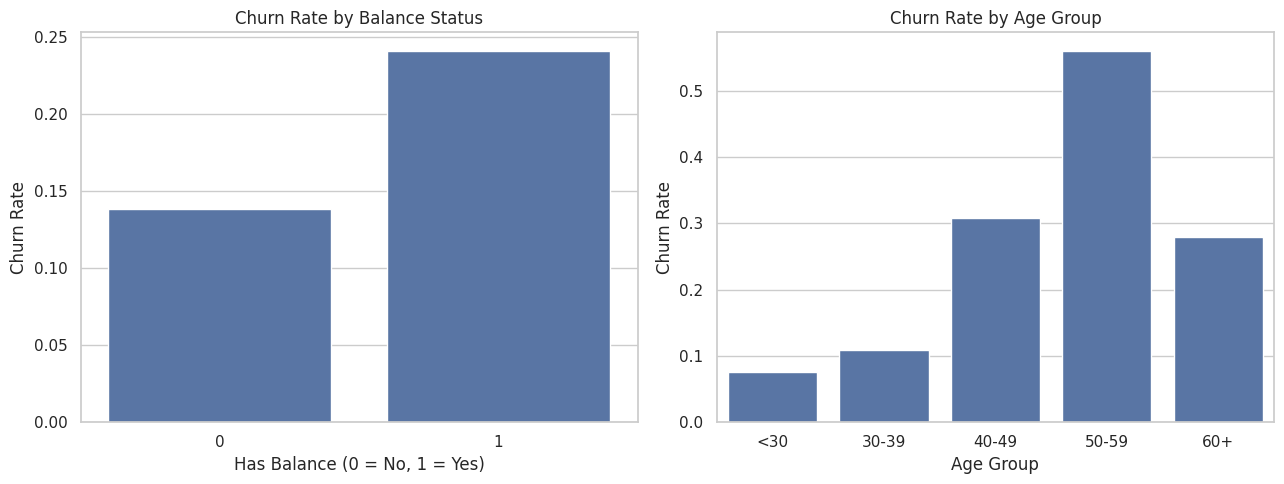

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))



sns.barplot(data=engineered_df, x="HasBalance", y="Exited", errorbar=None, ax=axes[0])

axes[0].set_title("Churn Rate by Balance Status")

axes[0].set_xlabel("Has Balance (0 = No, 1 = Yes)")

axes[0].set_ylabel("Churn Rate")



sns.barplot(data=engineered_df, x="AgeGroup", y="Exited", errorbar=None, ax=axes[1])

axes[1].set_title("Churn Rate by Age Group")

axes[1].set_xlabel("Age Group")

axes[1].set_ylabel("Churn Rate")



plt.tight_layout()

plt.show()

## 8. Validate and Save the Processed Dataset



The processed dataset retains the original columns and adds the two engineered features. Identifier-like columns remain for traceability at this stage; they will be excluded from model inputs during feature selection.



The generated CSV is stored under `data/processed/`. That directory is Git-ignored, so the dataset can be regenerated by executing this notebook.

In [8]:
assert engineered_df.shape == (len(df), len(df.columns) + 2)

assert engineered_df[["HasBalance", "AgeGroup"]].notna().all().all()

assert engineered_df["HasBalance"].isin([0, 1]).all()

assert engineered_df["AgeGroup"].cat.ordered



processed_dir = PROJECT_ROOT / "data/processed"

processed_dir.mkdir(parents=True, exist_ok=True)



processed_data_path = processed_dir / "european-bank-feature-engineered.csv"

engineered_df.to_csv(processed_data_path, index=False)



print(f"Processed dataset saved to: {processed_data_path}")

print(f"Final dataset shape: {engineered_df.shape}")

Processed dataset saved to: /home/dell/unified-mentor/ml-internship/projects/eurobank-customer-churn-prediction/data/processed/european-bank-feature-engineered.csv
Final dataset shape: (10000, 16)


## 9. Phase 4 Summary



- Two features were engineered: `HasBalance` and `AgeGroup`.

- Original features were preserved.

- Input validation enforces the customer age domain of 18–100 and nonnegative balances.

- The reusable implementation is maintained in `src/feature_engineering.py`.

- Automated tests are maintained in `tests/test_feature_engineering.py`.

- The processed dataset can be regenerated by running this notebook from the project directory.



### Important modeling note

Feature engineering decisions are based on exploratory analysis. Their predictive value must be assessed on held-out data in later phases. Any preprocessing that learns parameters from data must be fitted using training data only to avoid data leakage.